# 02 · Gold layer (SQL) → Analysis → Machine Learning → Save results

1. Build the **gold** tables with SQL (`sql/02_gold_layer.sql`)
2. Analyse the data with charts
3. Train a model that **predicts tomorrow's maximum temperature**
4. Save the model file + predictions back to SQL Server (`gold.ml_predictions`, `gold.model_metrics`, `gold.next_day_forecast`)

In [21]:
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DB_SERVER, DB_PORT, DB_USER, DB_PASSWORD, DB_NAME = "localhost", 1433, "sa", "Weather_Pass123!", "WeatherDB"
url = URL.create("mssql+pymssql", username=DB_USER, password=DB_PASSWORD,
                 host=DB_SERVER, port=DB_PORT, database=DB_NAME)
engine = create_engine(url)

## 1. Build the GOLD layer with SQL

In [22]:
def run_sql_file(path, engine):
    sql = Path(path).read_text(encoding="utf-8")
    batches = [b.strip() for b in sql.split("\nGO") if b.strip()]
    with engine.begin() as conn:                      # one transaction, commits at the end
        for batch in batches:
            if batch.upper().startswith("USE "):
                continue
            conn.execute(text(batch))

run_sql_file("../sql/02_gold_layer.sql", engine)



In [23]:
with engine.connect() as conn:
    print(pd.read_sql("""
        SELECT t.name AS table_name, SUM(p.rows) AS row_count
        FROM sys.tables t JOIN sys.partitions p ON p.object_id = t.object_id AND p.index_id IN (0,1)
        WHERE SCHEMA_NAME(t.schema_id) = 'gold'
        GROUP BY t.name
    """, conn))

             table_name  row_count
0             city_kpis          5
1              dim_city          5
2    fact_daily_weather          5
3  monthly_city_summary          5
4        season_summary          5
5         weather_daily          5


In [24]:
kpis    = pd.read_sql("SELECT * FROM  silver.weather_daily ", engine)

In [25]:
kpis    = pd.read_sql("SELECT * FROM gold.city_kpis ORDER BY avg_temp DESC", engine)
monthly = pd.read_sql("SELECT * FROM gold.monthly_city_summary ORDER BY city, month_start", engine)
fact    = pd.read_sql("SELECT * FROM gold.fact_daily_weather ORDER BY city, [date]", engine,
                      parse_dates=["date"])
kpis

,city,first_date,last_date,days_count,avg_temp,record_high,record_low,avg_yearly_precip_mm,rainy_days_pct
0,Dubai,2026-10-16,2026-10-16,1,31.6,35.3,27.4,0.0,0.0
1,Baku,2026-10-16,2026-10-16,1,22.4,25.1,20.4,0.0,0.0
2,New York,2026-10-16,2026-10-16,1,18.4,23.9,14.1,5.8,100.0
3,London,2026-10-16,2026-10-16,1,13.3,15.7,8.9,5.4,100.0
4,Berlin,2026-10-16,2026-10-16,1,11.5,17.8,6.1,0.0,0.0


In [26]:
fact.to_sql("weather_daily", engine, schema="gold", if_exists="replace",
                 index=False, chunksize=100, method="multi")

5

In [27]:
kpis    = pd.read_sql("SELECT * FROM gold.weather_daily", engine)

In [28]:
kpis

,city_id,city,date,year,month,season,temp_max,temp_min,temp_mean,temp_range,precipitation_mm,wind_speed_max_kmh,sunshine_hours,is_rainy
0,1,Baku,2026-10-16,2026,10,Autumn,25.1,20.4,22.4,4.7,0.0,18.6,10.58,0
1,2,Berlin,2026-10-16,2026,10,Autumn,17.8,6.1,11.5,11.7,0.0,9.3,9.83,0
2,3,Dubai,2026-10-16,2026,10,Autumn,35.3,27.4,31.6,7.9,0.0,13.0,10.72,0
3,4,London,2026-10-16,2026,10,Autumn,15.7,8.9,13.3,6.8,5.4,15.9,7.00,1
4,5,New York,2026-10-16,2026,10,Autumn,23.9,14.1,18.4,9.8,5.8,17.7,8.56,1


## 2. Analysis

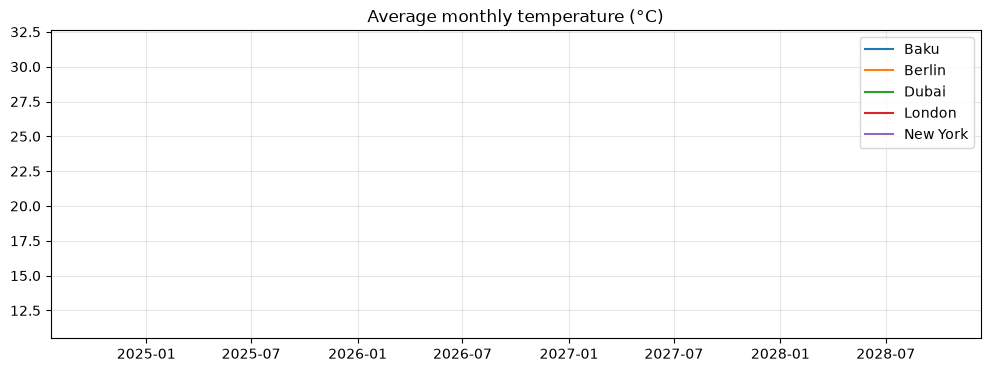

In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
for city, g in monthly.groupby("city"):
    ax.plot(pd.to_datetime(g["month_start"]), g["avg_temp"], label=city)
ax.set_title("Average monthly temperature (°C)")
ax.legend(); ax.grid(alpha=.3)
plt.show()

In [30]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]
season = pd.read_sql("SELECT * FROM gold.season_summary", engine)
season.pivot(index="city", columns="season", values="avg_temp")[season_order] \
      .plot(kind="bar", figsize=(10, 4), title="Average temperature by season (°C)", rot=0)
plt.grid(axis="y", alpha=.3); plt.show()

kpis.set_index("city")["rainy_days_pct"].sort_values() \
    .plot(kind="barh", figsize=(8, 3), title="Share of rainy days (%)")
plt.show()

KeyError: "['Winter', 'Spring', 'Summer'] not in index"

In [ ]:
num_cols = ["temp_max", "temp_min", "temp_mean", "temp_range", "precipitation_mm",
            "wind_speed_max_kmh", "sunshine_hours"]
corr = fact[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Correlation between weather measures")
plt.tight_layout(); plt.show()

## 3. Machine Learning — predict tomorrow's max temperature

**Features (what we know today):** city, day of year (as sin/cos so Dec 31 is close to Jan 1),
today's max/min/mean temperature, rain, wind, sunshine and yesterday's max temperature.
**Target:** next day's `temp_max`.

We split by **time** (last 20 % of dates = test), because in real life we predict the future from the past.

In [ ]:
FEATURES = ["city", "doy_sin", "doy_cos", "temp_max", "temp_min", "temp_mean",
            "precipitation_mm", "wind_speed_max_kmh", "sunshine_hours", "temp_max_prev_day"]
TARGET = "target_temp_max_next_day"


def build_features(data):
    d = data.sort_values(["city", "date"]).copy()
    doy = d["date"].dt.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    d["temp_max_prev_day"] = d.groupby("city")["temp_max"].shift(1)
    d[TARGET] = d.groupby("city")["temp_max"].shift(-1)
    return d


ml = build_features(fact).dropna(subset=["temp_max_prev_day", TARGET])

cutoff = ml["date"].quantile(0.8)
train, test = ml[ml["date"] <= cutoff], ml[ml["date"] > cutoff]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(f"train: {len(train)} rows (until {cutoff.date()}) | test: {len(test)} rows")

train: 0 rows (until NaT) | test: 0 rows


In [ ]:
numeric = [f for f in FEATURES if f != "city"]
prep = ColumnTransformer([
    ("city", OneHotEncoder(handle_unknown="ignore"), ["city"]),
    ("num", StandardScaler(), numeric),
])

models = {
    "LinearRegression": Pipeline([("prep", prep), ("model", LinearRegression())]),
    "RandomForest": Pipeline([("prep", prep), ("model", RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1))]),
}


def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


results = {"Baseline (tomorrow = today)": score(y_test, X_test["temp_max"])}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    results[name] = score(y_test, pipe.predict(X_test))

results_df = pd.DataFrame(results).T.round(3).sort_values("MAE")
results_df

ValueError: Found array with 0 sample(s) (shape=(0,)) while a minimum of 1 is required.

In [ ]:
best_name = results_df.drop(index="Baseline (tomorrow = today)")["MAE"].idxmin()
best_model = models[best_name]
print("Best model:", best_name)

test = test.copy()
test["predicted"] = best_model.predict(X_test)

city = "Baku"
g = test[test["city"] == city]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(g["date"] + pd.Timedelta(days=1), g[TARGET], label="Actual", lw=1.5)
ax.plot(g["date"] + pd.Timedelta(days=1), g["predicted"], label="Predicted", lw=1.2, ls="--")
ax.set_title(f"{city}: next-day max temperature — actual vs predicted ({best_name})")
ax.legend(); ax.grid(alpha=.3); plt.show()

In [ ]:
rf = models["RandomForest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Random Forest — feature importance")
plt.tight_layout(); plt.show()

## 4. Save the model and the results

* Model file → `models/weather_model.joblib` (used by Streamlit)
* `gold.ml_predictions` → every test prediction (great for Power BI)
* `gold.model_metrics` → metrics history (appended each run)
* `gold.next_day_forecast` → tomorrow's forecast for every city

In [ ]:
# Re-train the best model on ALL data before saving (more data = better model)
final_model = models[best_name]
final_model.fit(ml[FEATURES], ml[TARGET])

Path("../models").mkdir(exist_ok=True)
joblib.dump({
    "model": final_model,
    "model_name": best_name,
    "features": FEATURES,
    "target": TARGET,
    "metrics": results_df.loc[best_name].to_dict(),
    "cities": sorted(ml["city"].unique()),
    "trained_at": datetime.now().isoformat(timespec="seconds"),
}, "../models/weather_model.joblib")
print("model saved")

In [ ]:
run_time = pd.Timestamp.now()

# predictions on the test period
pred_table = pd.DataFrame({
    "city": test["city"],
    "forecast_date": (test["date"] + pd.Timedelta(days=1)).dt.date,
    "actual": test[TARGET].round(2),
    "predicted": test["predicted"].round(2),
})
pred_table["error"] = (pred_table["predicted"] - pred_table["actual"]).round(2)
pred_table["abs_error"] = pred_table["error"].abs()
pred_table["model_name"] = best_name
pred_table["created_at"] = run_time
pred_table.to_sql("ml_predictions", engine, schema="gold", if_exists="replace",
                  index=False, chunksize=200, method="multi")

# metrics history
metrics_table = results_df.reset_index(names="model_name")
metrics_table["is_best"] = (metrics_table["model_name"] == best_name).astype(int)
metrics_table["train_rows"], metrics_table["test_rows"] = len(train), len(test)
metrics_table["trained_at"] = run_time
metrics_table.to_sql("model_metrics", engine, schema="gold", if_exists="append", index=False)

# forecast for the day after the latest date of every city
latest = build_features(fact).groupby("city").tail(1)
forecast = pd.DataFrame({
    "city": latest["city"],
    "based_on_date": latest["date"].dt.date,
    "forecast_date": (latest["date"] + pd.Timedelta(days=1)).dt.date,
    "predicted_temp_max": final_model.predict(latest[FEATURES]).round(1),
    "model_name": best_name,
    "created_at": run_time,
})
forecast.to_sql("next_day_forecast", engine, schema="gold", if_exists="replace", index=False)
forecast

## 5. Check the saved results with SQL

In [ ]:
query = """
SELECT city,
       COUNT(*)                  AS predictions,
       ROUND(AVG(abs_error), 2)  AS mae,
       ROUND(AVG(error), 2)      AS avg_bias
FROM gold.ml_predictions
GROUP BY city
ORDER BY mae
"""
pd.read_sql(query, engine)

In [ ]:
pd.read_sql("SELECT TOP 10 * FROM gold.model_metrics ORDER BY trained_at DESC, MAE", engine)

✅ **Done.** Now start the dashboard: `streamlit run app/streamlit_app.py`
(or `docker compose up -d --build`) and connect Power BI to the `gold` schema — see README.